# Worksheet 4: Prepare the locked state $|\psi_{m,k}\rangle=D_kF|m\rangle$

**Task 4 of 5.** Put Tasks 1–3 together into **Alice's encoder** and study the state that travels through the channel.

```
 |0…0⟩ ─[ X gates ]─► |m⟩ ─[ QFT ]─► F|m⟩ ─[ D_k ]─► |ψ_{m,k}⟩ ──► channel
          task 1              task 2           task 3      task 4
```

What you'll do, in this order:

1. write the amplitudes of $|\psi_{m,k}\rangle$ on paper
2. compute the locked state with NumPy (ground truth)
3. build Alice's circuit
4. watch the state change gate by gate
5. prove three properties: equal magnitudes, orthonormal codewords per key, scrambling across keys
6. see why the order $D_kF$ (not $FD_k$) matters
7. build Eve's view (a mixture over keys)
8. record the full test set

### How to use this worksheet

- **📖 Read** cells explain a concept. **✍️ On paper** cells ask you to work something out by hand first.
- **✏️ TODO** cells are yours: replace `None` or the `raise NotImplementedError` with your own code.
- **✅ Check** cells test what you wrote. They print ✅ (correct), ❌ (what is wrong, not how to fix it) or ⏳ (not done yet). **Don't move on until you get ✅.**
- **💡 Hints** are folded. Open them only if you are stuck; Hint 1 is gentle, the last one names the exact function or gate.
- **🔀 Options** tables list the different ways to do a step. Choose one, and write your choice and reason in the decision log at the end, which you can reuse in the report.


## Setup


In [84]:
# Setup (given — nothing to solve here)
# If a package is missing:  !pip install qiskit matplotlib
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from qiskit.circuit.library import QFTGate, DiagonalGate, UnitaryGate

from lock_checks import *     # the automatic checks + plot_circles (keep lock_checks.py in this folder)

np.set_printoptions(precision=3, suppress=True, linewidth=130)
print("Qiskit", qiskit.__version__, "ready")

Qiskit 2.5.2 ready


## Paste your work from worksheets 1–3


In [85]:
# ✏️ paste
N_DEMO, N = 4, 6
d_demo, d, M = 2**N_DEMO, 2**N, 2**N
K, SEED, MODE = 4, 2026, "uniform"

def bits_of(m, n):
    return [(m >> q) & 1 for q in range(n)]

def ket(m, d):
    v = np.zeros(d, dtype=complex)
    v[m] = 1.0
    return v

def encode_message(m, n):
    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)
    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])
    return qc

def dft_matrix(n):
    d = 2 ** n
    x = np.arange(d)
    return np.exp(2j * np.pi * np.outer(x, x) / d) / np.sqrt(d)

def make_codebook(n, K, seed=2026, mode="uniform"):
    d = 2 ** n
    rng = np.random.default_rng(seed)
    if mode == "uniform":
        return rng.uniform(0.0, 2.0 * np.pi, size=(K, d))
    if mode == "binary":
        return np.pi * rng.integers(0, 2, size=(K, d))
    raise ValueError(f"unknown mode {mode!r}")

def D_matrix(theta_row):
    return np.diag(np.exp(1j * np.asarray(theta_row)))

def D_gate(theta_row):
    return DiagonalGate(list(np.exp(1j * np.asarray(theta_row))))

In [86]:
check_ket(ket); check_encode(encode_message); check_dft(dft_matrix)
check_codebook(make_codebook); check_D_matrix(D_matrix); check_D_gate(D_gate)
try:
    thetas      = make_codebook(N, K, SEED, MODE)        # project codebook
    thetas_demo = make_codebook(N_DEMO, K, SEED, MODE)   # small codebook for pictures
except NotImplementedError:
    thetas = thetas_demo = None
    print('⏳ paste your worksheet functions above first')

✅ ket(m, d) — length, normalization and position all correct
✅ encode_message(m, n) — every message prepares the right basis state (n = 3 and 6)
✅ dft_matrix(n) — matches the definition for n = 1..6
✅ make_codebook(n, K, seed, mode) — shape, range, reproducibility and both modes OK
✅ D_matrix(theta_row) — diagonal with entries e^{i theta}
✅ D_gate(theta_row) — gate matrix = diag(e^{i theta}) in Qiskit's ordering


---

## Step 4.1: On paper: the amplitudes of the locked state

✍️ Combine the formula of $F|m\rangle$ (worksheet 2) with $D_k|x\rangle = e^{i\theta_{k,x}}|x\rangle$ (worksheet 3). Write

$$|\psi_{m,k}\rangle = D_kF|m\rangle = \sum_x (\;?\;)\,|x\rangle .$$

Then answer:

- What is the **magnitude** of each amplitude?
- Its **phase** is a sum of two parts. Which part carries the message, and which the key?
- Compare with the paper's **Eq. (18)**. Which symbol there is your $D_k$, and which is your $F|m\rangle$?

📖 **Reading order:** operators act right to left ($|m\rangle$, then $F$, then $D_k$); circuit diagrams read left to right in the same order.


Combining
F
∣
m
⟩
=
1
d
∑
x
e
2
π
i
m
x
/
d
∣
x
⟩
F∣m⟩=
d
​

1
​
∑
x
​
e
2πimx/d
∣x⟩ with
D
k
∣
x
⟩
=
e
i
θ
k
,
x
∣
x
⟩
D
k
​
∣x⟩=e
iθ
k,x
​

∣x⟩:

∣
ψ
m
,
k
⟩
=
D
k
F
∣
m
⟩
=
1
d
∑
x
=
0
d
−
1
e

 
i
 ⁣
(
θ
k
,
x

- 2
  π
  m
  x
  /
  d
  )
  ∣
  x
  ⟩
  .
  ∣ψ
  m,k
  ​
  ⟩=D
  k
  ​
  F∣m⟩=
  d
  ​

1
​

x=0
∑
d−1
​
e
i(θ
k,x
​
+2πmx/d)
∣x⟩.
Magnitude of every amplitude:
1
/
d
1/
d
​
, independent of
m
m and
k
k.

Phase = (message part)
2
π
m
x
/
d
2πmx/d + (key part)
θ
k
,
x
θ
k,x
​
. The message contributes a linear ramp; the key contributes a random offset.

Paper Eq. (18): the paper's
U
k
U
k
​
is our
D
k
D
k
​
; the paper's
F
∣
m
⟩
F∣m⟩ (or
∣
m
~
⟩
∣
m
~
⟩ in Eq. 17) is our QFT output.


## Step 4.2: Ground truth with NumPy

🔀 **Options to compute the locked state**

| Option | How                                                   | Use for                               |
| ------ | ----------------------------------------------------- | ------------------------------------- |
| A      | matrix products with your NumPy functions             | ground truth                          |
| B      | Qiskit circuit + `Statevector.from_instruction`       | the project implementation (Step 4.3) |
| C      | `Statevector.from_int(...).evolve(gate).evolve(gate)` | inspecting after each gate (Step 4.4) |
| D      | your formula from Step 4.1, element by element        | fast in big loops                     |

Compute $|\psi_{5,2}\rangle$ for `N_DEMO` with option A (and D if you like).


In [87]:
# ✏️ TODO 4.2: locked state for m=5, k=2 with NumPy (use thetas_demo)
# ✏️ TODO 4.2
m, k = 5, 2
psi = D_matrix(thetas_demo[k]) @ dft_matrix(N_DEMO) @ ket(m, d_demo)

In [88]:
check_psi_numpy(psi, m, k, thetas_demo)

✅ locked state with NumPy


True

<details><summary>💡 Hint 1</summary>

Which matrix is closest to `ket(m, d)` in the product?

</details>

<details><summary>💡 Hint 2</summary>

`D_matrix(...) @ dft_matrix(...) @ ket(...)`

</details>


## Step 4.3: Alice's circuit

Write `lock_circuit(m, k, n, thetas)` that returns the full circuit from $|0\dots0\rangle$ to $|\psi_{m,k}\rangle$, and `locked_state(...)` that returns its `Statevector`. Reuse your functions: you should not need any new gate type. A `barrier` between parts makes the drawing readable.


In [89]:
# ✏️ TODO 4.3
# ✏️ TODO 4.3
def lock_circuit(m, k, n, thetas):
    qc = encode_message(m, n)
    qc.barrier()
    qc.append(QFTGate(n), range(n))
    qc.barrier()
    qc.append(D_gate(thetas[k]), range(n))
    return qc

def locked_state(m, k, n, thetas):
    return Statevector.from_instruction(lock_circuit(m, k, n, thetas))

In [90]:
check_lock_circuit(lock_circuit, thetas_demo)
check_lock_circuit(lock_circuit, thetas)

✅ lock_circuit(m, k, n, thetas) — Alice's encoder is correct
✅ lock_circuit(m, k, n, thetas) — Alice's encoder is correct


True

<details><summary>💡 Hint 1</summary>

Three pieces in order: your encoder, the QFT, the key gate for key `k`.

</details>

<details><summary>💡 Hint 2</summary>

`qc = encode_message(m, n)`, then `qc.append(QFTGate(n), range(n))`, then `qc.append(D_gate(thetas[k]), range(n))`.

</details>


## Step 4.4: Watch the state change, gate by gate

Use option C: start from `Statevector.from_int(m, d_demo)` and `.evolve(...)` one gate at a time. Draw each of the three stages with `plot_circles` and print the phases in degrees.

✍️ Predict first, then compare:

1. $|m\rangle$: …
2. $F|m\rangle$: …
3. $D_kF|m\rangle$: …

Then draw $|\psi_{m,k}\rangle$ for the **same $m$** and all $K$ keys. What stays the same and what changes?


|m> phases: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


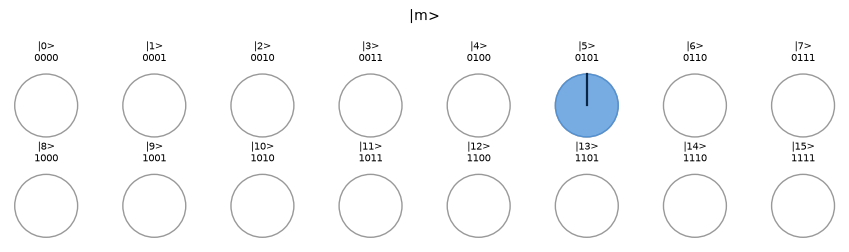

F|m> phases: [  0.  112.5 225.  337.5  90.  202.5 315.   67.5 180.  292.5  45.  157.5 270.   22.5 135.  247.5]


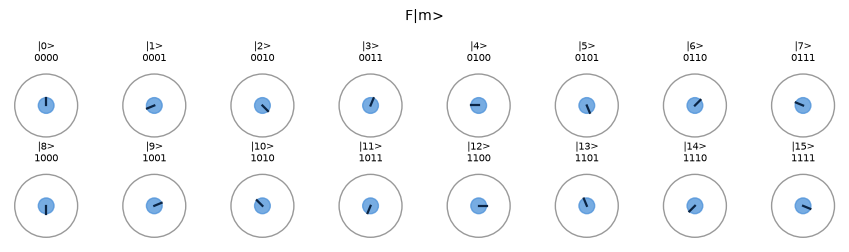

D_k F|m> phases: [287.1 330.9 349.2 318.4 292.8 358.3 279.2 182.5  70.6  45.5 139.2  49.8 352.  200.  343.8 315.5]


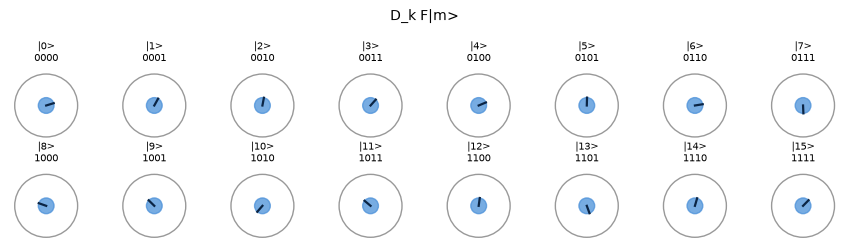

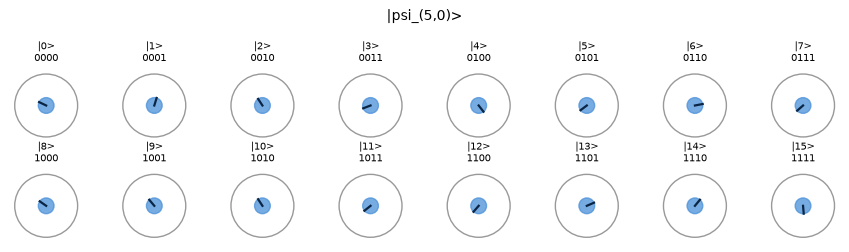

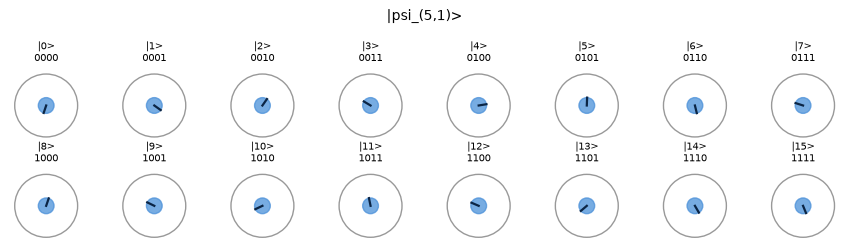

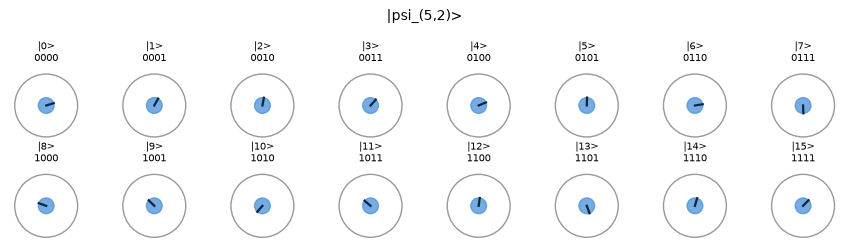

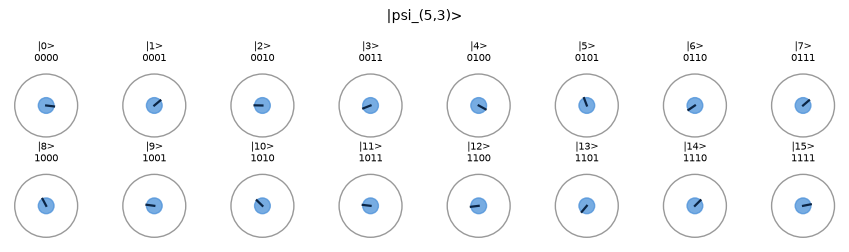

In [91]:
# ✏️ TODO 4.4: three stages + same m with every key
# ✏️ TODO 4.4
m, n = 5, N_DEMO
d_n = 2 ** n

sv0 = Statevector.from_int(m, d_n)                       # |m>
sv1 = sv0.evolve(QFTGate(n))                             # F|m>
sv2 = sv1.evolve(D_gate(thetas_demo[2]))                 # D_k F|m>

for label, sv in (("|m>", sv0), ("F|m>", sv1), ("D_k F|m>", sv2)):
    phases = np.degrees(np.angle(sv.data)) % 360
    print(label, "phases:", np.round(phases, 1))
    plot_circles(sv, label)
    plt.show()

# Same m, every key
for k in range(K):
    svk = locked_state(m, k, n, thetas_demo)
    plot_circles(svk, f"|psi_({m},{k})>")
    plt.show()

## Step 4.5: Property 1, every component has magnitude $1/\sqrt d$

📖 This is one of the paper bullets you must explain: _why all computational-basis components have the same magnitude._ You found the reason on paper in Step 4.1. Now verify it for **every** $(m,k)$ at project size: compute the largest deviation of any probability from $1/d$.

✍️ Consequence for Eve: what does a direct measurement in the computational basis tell her about $m$?


In [92]:
# ✏️ TODO 4.5: loop over all (m, k); max_dev = largest |p(x) - 1/d| you see
# ✏️ TODO 4.5
max_dev = 0.0
for m in range(M):
    for k in range(K):
        sv = locked_state(m, k, N, thetas)
        probs = np.abs(sv.data) ** 2
        max_dev = max(max_dev, np.max(np.abs(probs - 1.0 / d)))
print("max deviation:", max_dev)

max deviation: 5.204170427930421e-17


In [93]:
check_uniform(max_dev)

✅ all magnitudes equal


True

## Step 4.6: Property 2, for a fixed key the codewords are orthonormal

✍️ **On paper:** compute $\langle\psi_{m',k}|\psi_{m,k}\rangle$ using $(D_kF)^\dagger = F^\dagger D_k^\dagger$ and the unitarity of both. What do you get?

📖 Orthonormal codewords can be told apart perfectly by one measurement, so Bob (who knows $k$) can decode with probability 1. Paper Sec. II.A says exactly this.

🔀 **Options to compute all overlaps**

| Option | How                                                                                                     |
| ------ | ------------------------------------------------------------------------------------------------------- |
| A      | double loop with `np.vdot`                                                                              |
| B      | put the $M$ codewords of key $k$ as **columns** of a matrix $\Psi_k$, then Gram $=\Psi_k^\dagger\Psi_k$ |

Make a list `grams` with one $M\times M$ Gram matrix per key.


In [94]:
# ✏️ TODO 4.6
grams = []
for k in range(K):
    Psi = np.column_stack([
        locked_state(m, k, N, thetas).data for m in range(M)
    ])
    grams.append(Psi.conj().T @ Psi)

In [95]:
check_grams(grams, K, M)

✅ codewords orthonormal for each key


True

<details><summary>💡 Hint 1</summary>

Build $\Psi_k$ with `np.column_stack([... for m in range(M)])`.

</details>

<details><summary>💡 Hint 2</summary>

Gram matrix: `Psi.conj().T @ Psi`.

</details>


## Step 4.7: Property 3, different keys scramble each other

📖 For two **different** keys $k_1\neq k_2$, compute the $M\times M$ matrix $O[m',m]=|\langle\psi_{m',k_2}|\psi_{m,k_1}\rangle|^2$. Show it as a heatmap (`plt.imshow`) next to the same-key version, and print its mean and max.

✍️ Before computing: if the codeword of key $k_1$ were spread perfectly evenly over the basis of key $k_2$, what would every entry be?


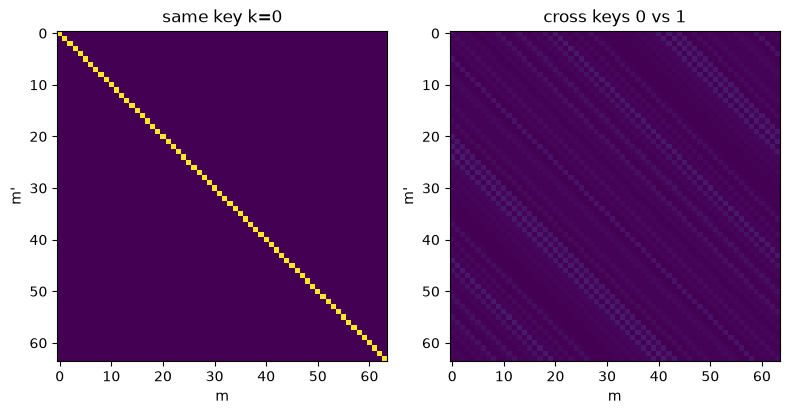

cross mean: 0.015625000000000003  cross max: 0.07217287811263984


In [96]:
# ✏️ TODO 4.7
k1, k2 = 0, 1
Psi1 = np.column_stack([locked_state(m, k1, N, thetas).data for m in range(M)])
Psi2 = np.column_stack([locked_state(m, k2, N, thetas).data for m in range(M)])
O = np.abs(Psi2.conj().T @ Psi1) ** 2

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(np.abs(grams[k1]) ** 2, vmin=0, vmax=1)
axes[0].set_title(f"same key k={k1}")
axes[1].imshow(O, vmin=0, vmax=1)
axes[1].set_title(f"cross keys {k1} vs {k2}")
for ax in axes:
    ax.set_xlabel("m"); ax.set_ylabel("m'")
plt.tight_layout(); plt.show()

print("cross mean:", O.mean(), " cross max:", O.max())

In [97]:
check_cross(O, thetas, k1, k2)

✅ cross-key overlaps


True

## Step 4.8: Does the order matter? ($D_kF$ vs $FD_k$)

✍️ **On paper:** what is $D_k|m\rangle$ for a basis state? Then what is $FD_k|m\rangle$?

Then test it: build both $FD_k|42\rangle$ (wrong order) and $D_kF|42\rangle$ (correct), and compare each with the unlocked $F|42\rangle$ **up to a global phase** (`Statevector.equiv`).


In [98]:
# ✏️ TODO 4.8
n = N
m_secret = 42
F_g = QFTGate(n)
D_g = D_gate(thetas[0])

sv_m = Statevector.from_int(m_secret, d)
sv_F = sv_m.evolve(F_g)                          # reference: F|m>

# Encrypting order (variable name "wrong_equals_unlocked" in the check):
#   F D_k |m>  -> global phase only, equals F|m> up to a phase
sv_FDk = sv_m.evolve(D_g).evolve(F_g)

# Locking order (variable name "right_equals_unlocked" in the check):
#   D_k F |m>  -> NOT equal to F|m>
sv_DkF = sv_m.evolve(F_g).evolve(D_g)

wrong_equals_unlocked = sv_FDk.equiv(sv_F)   # True
right_equals_unlocked = sv_DkF.equiv(sv_F)   # False

In [99]:
check_wrong_order(wrong_equals_unlocked, right_equals_unlocked)

✅ wrong order experiment


True

❓ One sentence for your notes: why must the QFT come **before** the key phases?


## Step 4.9: Eve's point of view, an ensemble of codewords

📖 Eve knows the protocol and the public codebook $\{D_k\}$, but not $k$. For message $m$ she gets one of the $K$ states $|\psi_{m,k}\rangle$, each with probability $1/K$. Her description is the **density matrix**

$$\rho_m=\frac1K\sum_{k}|\psi_{m,k}\rangle\langle\psi_{m,k}|.$$

This answers the paper bullet _"why Eve, without the key, receives an ensemble of possible codewords"_ (paper Eq. 21 from Eve's side).

🔀 **Options**

| Option | How                                                                  |
| ------ | -------------------------------------------------------------------- |
| A      | NumPy: sum of outer products `np.outer(psi, psi.conj())`             |
| B      | Qiskit: `DensityMatrix(statevector)`, add them up, multiply by `1/K` |

Build $\rho_{42}$ at project size. Then compute:

- its trace (should be 1)
- its purity $\mathrm{Tr}\,\rho^2$. ✍️ Predict: pure state → ?, equal mix of $K$ nearly orthogonal states → ?
- its computational-basis probabilities (uniform?)
- the probability of $m=42$ if Eve applies only the public $F^\dagger$ (e.g. `DensityMatrix.evolve`)


In [101]:
# ✏️ TODO 4.9
m_eve = 42
states = [locked_state(m_eve, k, N, thetas).data for k in range(K)]

# Option A: pure NumPy
rho_np = sum(np.outer(s, s.conj()) for s in states) / K

# Option B: Qiskit — build rho, then work on the raw arrays
rho = sum((DensityMatrix(s) for s in states),
          DensityMatrix(np.zeros((d, d), dtype=complex))) / K

rho_arr = np.asarray(rho.data)

print("trace:          ", np.real(np.trace(rho_arr)))
print("purity Tr ρ² : ", np.real(np.trace(rho_arr @ rho_arr)))
print("target 1/K:     ", 1 / K)
print("computational probs (first 8):", np.round(np.real(np.diag(rho_arr))[:8], 4))
print("uniform target:", 1 / d)

# Eve only has F^dagger (no key):
rho_after_Fdag = rho.evolve(QFTGate(N).inverse())
p_42 = np.real(np.asarray(rho_after_Fdag.data)[m_eve, m_eve])
print("Eve's guess P(m=42):", p_42)

# Cross-check with the NumPy version
print("numpy vs qiskit:", np.allclose(rho_np, rho_arr))

trace:           0.9999999999999999
purity Tr ρ² :  0.2719628639281543
target 1/K:      0.25
computational probs (first 8): [0.016 0.016 0.016 0.016 0.016 0.016 0.016 0.016]
uniform target: 0.015625
Eve's guess P(m=42): 0.024304302728761502
numpy vs qiskit: True


In [102]:
check_rho(rho, 42, thetas)

✅ Eve's density matrix — purity = 0.272


True

## Step 4.10: Record the full test set

📖 Brief: _"Record the message and key used for each experiment so that the correct decoding result is always known."_ For $n\le6$, use all $M\cdot K$ pairs.

🔀 **Options**

| Option | Structure                                                  |
| ------ | ---------------------------------------------------------- |
| A      | a list of dicts `{"m": …, "k": …}`                         |
| B      | a `pandas.DataFrame` (handy for the averages in tasks 7–8) |
| C      | also a NumPy array of all locked states, shape `(K, M, d)` |


In [103]:
# ✏️ TODO 4.10
experiments = [
    {"m": m, "k": k, "state": locked_state(m, k, N, thetas).data}
    for m in range(M) for k in range(K)
]

# Also a NumPy array, shape (K, M, d)
all_states = np.array([[locked_state(m, k, N, thetas).data
                        for m in range(M)] for k in range(K)])
print("len(experiments):", len(experiments), "  all_states.shape:", all_states.shape)

len(experiments): 256   all_states.shape: (4, 64, 64)


In [104]:
check_records(experiments, M, K)

✅ experiment records — 256 pairs


True

---

## Self-check questions

1. Why must $F$ come before $D_k$?
2. What does Eve learn from measuring directly in the computational basis?
3. Why is $\mathrm{Tr}\,\rho_m^2\approx1/K$?

<details><summary>Answers</summary>

1. On a basis state a diagonal operator is only a global phase; $F$ first spreads $|m\rangle$ over all basis states.
2. Nothing: the distribution is exactly uniform for every $m$.
3. $\rho_m$ is an equal mixture of $K$ almost-orthogonal pure states.
</details>

## Decision log

| Step                    | Options                            | My choice | Why |
| ----------------------- | ---------------------------------- | --------- | --- |
| 4.2 computing the state | NumPy / circuit / evolve / formula |           |     |
| 4.6 overlaps            | loops / matrix                     |           |     |
| 4.9 Eve's state         | NumPy / DensityMatrix              |           |     |
| 4.10 records            | dicts / DataFrame / + array        |           |     |

✅ All green? Continue with **Worksheet 5 (decoding)**.
